# TV2 — từ dữ liệu AAPL đến mẫu học có thể kiểm chứng
        Mục tiêu: chuẩn bị 30 phiên lịch sử để dự báo 1 hoặc 5 phiên. Notebook gọi backend thật; không nhân bản pipeline.
        Các cell có dữ liệu thật, kiểm tra/assertions và đường dẫn log. Run All chạy tests/audit lại và tạo evidence ID mới, không fit lại scaler hoặc sửa snapshot.
        **Phạm vi:** preprocessing đã kiểm chứng local; xác nhận máy thành viên khác còn chờ. Không có kết quả huấn luyện/MAE/RMSE.
        Đọc cùng `docs/TV2_Setup_and_Handoff.md`, `reports/audits/TV2_Final_Handoff.md`. Chạy từ workspace có artifacts, kernel Python `.venv/tv3_review_env`.

## Cấu hình và môi trường đang chạy

In [1]:
from pathlib import Path
import sys, json, os, subprocess, hashlib
from datetime import datetime, timezone
import importlib.metadata as packages
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'backend/data/preparation/snapshot.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
VERSION = 'aapl_2015_2025_acq_20261119T141302002415Z'
SCALER_DIR = ROOT/'artifacts/scalers/aapl_scaler_20261120T124720810874Z'
PREPARED_DIR = ROOT/'data/prepared/tv2_prepared_20261122T145943242978Z'
print('Executed UTC:', datetime.now(timezone.utc).isoformat())
print('Python:', sys.executable)
display(pd.DataFrame([{'package':n, 'version':packages.version(n)} for n in ['numpy','pandas','scikit-learn','torch','pytest']]))

def run_check(script, *args):
    env = dict(os.environ, OMP_NUM_THREADS='1', MKL_NUM_THREADS='1', PYTHONIOENCODING='utf-8')
    run = subprocess.run([sys.executable, '-X', 'utf8', str(ROOT/'scripts'/script), *args], cwd=ROOT, env=env, capture_output=True, text=True, encoding='utf-8')
    print(run.stdout)
    if run.returncode: raise RuntimeError(run.stderr or run.stdout)
    return json.loads(run.stdout)

Executed UTC: 2026-11-23T02:42:19.042704+00:00
Python: D:\learn_DeepLearning\Project_course-work\.venv\tv3_review_env\Scripts\python.exe


,package,version
0,numpy,2.4.4
1,pandas,3.0.6
2,scikit-learn,1.9.1
3,torch,2.14.1
4,pytest,9.2.0


## 1. Module nền và hợp đồng đầu vào
        Các helper kiểm tra cột/ngày/ticker/giá hữu hạn và shape, không âm thầm loại dòng. Source trong backend/data/preparation và transforms.
        Cell dưới hiển thị interface thật để liên hệ mã nguồn và bước xử lý.

In [2]:
import inspect
from backend.data.preparation.preparation import split_data, fit_scaler
from backend.data.transforms.scaling import scale, inverse_scale
display(pd.DataFrame([{'function':fn.__name__, 'signature':str(inspect.signature(fn)), 'source':str(Path(inspect.getfile(fn)).relative_to(ROOT))} for fn in [split_data,fit_scaler,scale,inverse_scale]]))

,function,signature,source
0,split_data,(validated_file_path: 'str | pd.DataFrame') ->...,backend\data\preparation\preparation.py
1,fit_scaler,(train_prices: 'np.ndarray') -> 'StandardScaler',backend\data\preparation\preparation.py
2,scale,"(values: 'np.ndarray', scaler: 'StandardScaler...",backend\data\transforms\scaling.py
3,inverse_scale,"(scaled_values: 'np.ndarray', scaler: 'Standar...",backend\data\transforms\scaling.py


## 2. Tiếp nhận snapshot TV1
        Xác minh 5 artifacts/version/hash/provenance/schema/giá và lịch tham chiếu, không tải lại hoặc cleaning. NASDAQ trong thư viện ánh xạ XNYS; giá adjusted là hồi cứu, không coi là backtest point-in-time hoàn hảo.

In [3]:
from backend.data.preparation.snapshot import load_tv1_snapshot
from backend.artifacts.scaler import load_scaler
from backend.artifacts.prepared import load_prepared_modes
snapshot = load_tv1_snapshot(ROOT, VERSION)
data = snapshot['data']
scaler, scaler_manifest = load_scaler(SCALER_DIR, expected_dataset_version=VERSION, expected_source_hashes=snapshot['acceptance']['hashes'])
modes, prepared_manifest = load_prepared_modes(PREPARED_DIR, expected_dataset_version=VERSION, expected_source_hashes=snapshot['acceptance']['hashes'], expected_scaler_id=scaler_manifest['scaler_id'])
assert snapshot['acceptance']['passed']
display(data.head())
print('Snapshot rows:', len(data), '| dates:', data.date.iloc[0], '→', data.date.iloc[-1])

,date,ticker,adjusted_close,dataset_version
0,2015-01-02,AAPL,24.153402,aapl_2015_2025_acq_20261119T141302002415Z
1,2015-01-05,AAPL,23.472971,aapl_2015_2025_acq_20261119T141302002415Z
2,2015-01-06,AAPL,23.475178,aapl_2015_2025_acq_20261119T141302002415Z
3,2015-01-07,AAPL,23.804344,aapl_2015_2025_acq_20261119T141302002415Z
4,2015-01-08,AAPL,24.718971,aapl_2015_2025_acq_20261119T141302002415Z


Snapshot rows: 2766 | dates: 2015-01-02 → 2025-12-31


In [4]:
display(pd.DataFrame([{'check':name, 'passed':value} for name,value in snapshot['acceptance']['checks'].items()]))
display(pd.DataFrame([{'artifact':name, 'sha256':value} for name,value in snapshot['acceptance']['hashes'].items()]))

,check,passed
0,source_provenance,True
1,quality_passed_for_same_snapshot,True
2,validation_passed_for_same_version,True
3,validation_source_hashes,True
4,validated_hash,True
5,validated_path_link,True
6,exact_four_column_schema,True
7,row_count_preserved,True
8,dates_valid_unique_ordered,True
9,all_rows_AAPL,True


,artifact,sha256
0,raw,cbcadbc002d05bc27a573114b9bb73b930733585b7823d...
1,metadata,71213959ec9c111a1826db9058dc41f61772af9a0324a4...
2,validated,ee56f9c782ac9e938985c680a9015d1ae198982e7d1cdd...
3,validation_report,4c28421c1488cfa3451fbd9661eed9fc4874a9295389e9...
4,quality_audit,f78e41b5006679a32aa97e454d3597ec0847979bcc727c...


## 3. Chia tập theo ngày target, giữ nguyên lịch sử
        Train2015–2022, validation2023, test2024–2025. Input được dùng lịch sử đã quan sát từ tập trước. Số phiên khác số mẫu do cần đủ lookback/target.

,split,sessions,first,last
0,train,2014,2015-01-02,2022-12-30
1,val,250,2023-01-03,2023-12-29
2,test,502,2024-01-02,2025-12-31


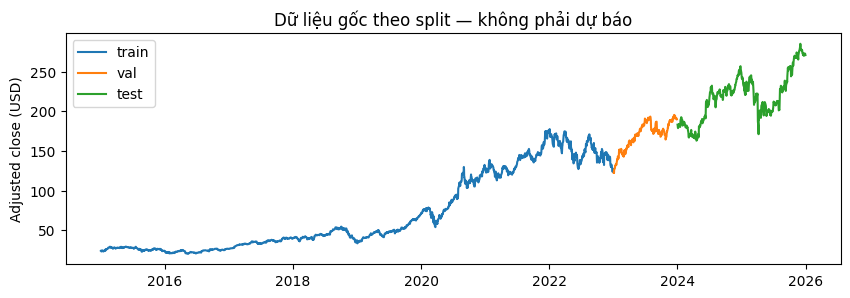

In [5]:
from backend.data.preparation.preparation import create_split_plan
plan = create_split_plan(data)
display(pd.DataFrame([{'split':s,'sessions':len(idx),'first':data.date.iloc[idx[0]],'last':data.date.iloc[idx[-1]]} for s,idx in plan['target_indices'].items()]))
import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize=(10,3))
for s,idx in plan['target_indices'].items(): ax.plot(pd.to_datetime(data.date.iloc[idx]),data.adjusted_close.iloc[idx],label=s)
ax.set(ylabel='Adjusted close (USD)',title='Dữ liệu gốc theo split — không phải dự báo'); ax.legend(); plt.show()

## 4. Scaler chỉ fit train
        Scaler hiện có đã fit2014 giá train và được load lại, không fit trong notebook. Metadata liên kết ngày/version/hashes; không refit với validation/test.

In [6]:
meta = scaler_manifest['metadata']
display(pd.DataFrame([{'scaler_id':scaler_manifest['scaler_id'],'fit_first':meta['fit_first_date'],'fit_last':meta['fit_last_date'],'fit_rows':meta['fit_row_count'],'mean_USD':scaler.mean_[0],'scale_USD':scaler.scale_[0],'dtype':str(scaler.mean_.dtype)}]))
assert meta['fit_split']=='train' and meta['fit_last_date']<='2022-12-31'

,scaler_id,fit_first,fit_last,fit_rows,mean_USD,scale_USD,dtype
0,aapl_scaler_20261120T124720810874Z,2015-01-02,2022-12-30,2014,70.088454,48.587429,float64


## 5. Scale và inverse về USD
        z=(P−mean_train)/scale_train. Kiểm tra số học không phải sai số dự báo. Không làm tròn trước khi kiểm tra, không clip z âm.

In [7]:
values = data.adjusted_close.iloc[[0,2014,2264,-1]].to_numpy().reshape(-1,1)
z = scale(values,scaler); restored = inverse_scale(z,scaler)
np.testing.assert_allclose(restored,values,rtol=1e-12,atol=1e-12)
display(pd.DataFrame({'price_USD':values.ravel(),'z':z.ravel(),'inverse_USD':restored.ravel(),'absolute_numeric_error':np.abs(restored-values).ravel()}))

,price_USD,z,inverse_USD,absolute_numeric_error
0,24.153402,-0.945410,24.153402,0.0
1,122.783440,1.084539,122.783440,0.0
2,183.264771,2.329333,183.264771,0.0
3,270.916168,4.133327,270.916168,0.0


## 6. Cửa sổ một bước
        X=(B,30,1), y=(B,1). Mỗi input kết thúc ở origin, target là phiên kế tiếp trong snapshot. Chỉ30 phiên đầu train thiếu lịch sử; không bỏ30 target đầu val/test.

In [8]:
display(pd.DataFrame([{'split':s,'samples':b['num_samples'],'X_shape':str(b['X'].shape),'y_shape':str(b['y'].shape),'excluded_history':b['excluded_insufficient_history']} for s,b in modes[1]['splits'].items()]))
b = modes[1]['splits']['val']; inp,tgt = b['inputs'][0],b['targets'][0]
display(pd.DataFrame({'input_date':inp['input_dates'],'raw_input_USD':inp['input_values'].ravel()}))
display(pd.DataFrame({'target_date':tgt['target_dates'],'raw_target_USD':tgt['target_values']}))
assert inp['forecast_origin'] < tgt['target_dates'][0]

,split,samples,X_shape,y_shape,excluded_history
0,train,1984,"(1984, 30, 1)","(1984, 1)",30
1,val,250,"(250, 30, 1)","(250, 1)",0
2,test,502,"(502, 30, 1)","(502, 1)",0


,input_date,raw_input_USD
0,2022-11-17,147.964508
1,2022-11-18,148.524109
2,2022-11-21,145.304077
3,2022-11-22,147.434357
4,2022-11-23,148.308121
5,2022-11-25,145.402237
6,2022-11-28,141.583359
7,2022-11-29,138.589111
8,2022-11-30,145.323715
9,2022-12-01,145.598541


,target_date,raw_target_USD
0,2023-01-03,122.78344


## 7. Direct multi-output5 bước
        X=(B,30,1), y=(B,5);5 target phải cùng split. Loại4 candidate cuối train/val vì cắt ranh giới,4 cuối test vì chưa đủ tương lai. Không recursive.

In [9]:
display(pd.DataFrame([{'split':s,'samples':b['num_samples'],'X_shape':str(b['X'].shape),'y_shape':str(b['y'].shape),'cross_split':b['excluded_cross_split_targets'],'incomplete':b['excluded_incomplete_targets']} for s,b in modes[5]['splits'].items()]))
tgt = modes[5]['splits']['test']['targets'][-1]
display(pd.DataFrame({'horizon_step':tgt['horizon_step'],'target_date':tgt['target_dates'],'raw_target_USD':tgt['target_values']}))

,split,samples,X_shape,y_shape,cross_split,incomplete
0,train,1980,"(1980, 30, 1)","(1980, 5)",4,0
1,val,246,"(246, 30, 1)","(246, 5)",4,0
2,test,498,"(498, 30, 1)","(498, 5)",0,4


,horizon_step,target_date,raw_target_USD
0,1,2025-12-24,272.859375
1,2,2025-12-26,272.450836
2,3,2025-12-29,272.809601
3,4,2025-12-30,272.131897
4,5,2025-12-31,270.916168


## 8. Input/target tách biệt, ID/version/ngày/shape
        Chỉ input được đi vào adapter inference. Các record phải khớp snapshot và scaled arrays. Cell dưới chạy lại kiểm tra cả hai chế độ, không fit model/scaler.

In [10]:
from backend.data.preparation.contracts import validate_window_result,build_inference_inputs
display(pd.DataFrame([validate_window_result(result,data,scaler) for result in modes.values()]))
b=modes[1]['splits']['val']; only=build_inference_inputs(b['inputs'],scaler)
np.testing.assert_array_equal(only['X'],b['X'])
print('Input-only keys:',list(only), '| Target fields:',list(b['targets'][0]))

,passed,forecast_length,sample_count,split_counts
0,True,1,2736,"{'train': 1984, 'val': 250, 'test': 502}"
1,True,5,2724,"{'train': 1980, 'val': 246, 'test': 498}"


Input-only keys: ['inputs', 'X'] | Target fields: ['sample_id', 'target_dates', 'target_values', 'split', 'horizon_step']


## 9. Tests và audit leakage
        Chạy suite TV2 thật; không skip. Audit độc lập train moments/coverage, thay giá tương lai trong bản sao để kiểm input quá khứ không đổi. Có12 ví dụ đối chiếu ngày/giá trong log; không sửa snapshot.

In [11]:
tv2_tests = run_check('run_tv2_checks.py')
assert tv2_tests['passed']

{
  "passed": true,
  "tests_run": 51,
  "failures": 0,
  "errors": 0,
  "skips": 0,
  "evidence": "D:\\learn_DeepLearning\\Project_course-work\\logs\\audit\\tv2_tests_20261123T024235052317Z\\summary.json"
}



In [12]:
leakage_run = run_check('audit_tv2_leakage.py','--dataset-version',VERSION,'--scaler-dir',str(SCALER_DIR))
leakage = json.loads(Path(leakage_run['evidence']).read_text(encoding='utf-8'))
assert leakage['passed']
display(pd.DataFrame([{'mode':m['forecast_length'],**p} for m in leakage['modes'] for p in m['future_price_perturbations']]))

{
  "passed": true,
  "fit_rows": 2014,
  "modes": [
    {
      "forecast_length": 1,
      "split_counts": {
        "train": 1984,
        "val": 250,
        "test": 502
      },
      "future_price_perturbations": [
        {
          "cutoff": "2023-01-01",
          "unchanged_past_inputs": 1985,
          "future_target_changed": true
        },
        {
          "cutoff": "2024-01-01",
          "unchanged_past_inputs": 2235,
          "future_target_changed": true
        }
      ]
    },
    {
      "forecast_length": 5,
      "split_counts": {
        "train": 1980,
        "val": 246,
        "test": 498
      },
      "future_price_perturbations": [
        {
          "cutoff": "2023-01-01",
          "unchanged_past_inputs": 1981,
          "future_target_changed": true
        },
        {
          "cutoff": "2024-01-01",
          "unchanged_past_inputs": 2227,
          "future_target_changed": true
        }
      ]
    }
  ],
  "evidence": "D:\\learn_DeepLearni

,mode,cutoff,unchanged_past_inputs,future_target_changed
0,1,2023-01-01,1985,True
1,1,2024-01-01,2235,True
2,5,2023-01-01,1981,True
3,5,2024-01-01,2227,True


## 10. Bàn giao và tái lập
        Gói ZIP hiện có chứa source tại thời điểm đóng gói22/11/2026, không tự cập nhật theo notebook này hoặc code TV3 mới. Cell kiểm hash ZIP và hiển thị evidence venv sạch/gói giải nén đã chạy; chưa có xác nhận máy thành viên khác.

In [13]:
archive=ROOT/'artifacts/releases/TV2_Handoff_20261122T145943242978Z.zip'
digest=hashlib.sha256(archive.read_bytes()).hexdigest()
assert digest=='2102c638b44cae2b078e1f67fea60735f3273ccd0bc8455812b4a3e35c3b1baa'
receipt=json.loads((ROOT/'logs/audit/tv2_handoff_repro_20261122T150046833893Z/verify_summary.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'zip':archive.name,'sha256':digest,'clean_local_verify':receipt['passed'],'recipient_machine_verified':receipt['recipient_machine_verified']}]))
display(Markdown('**Kết luận TV2:** kỹ thuật local đã kiểm chứng; chờ xác nhận liên máy. Tests/audit không chứng minh mô hình dự báo tốt.'))

,zip,sha256,clean_local_verify,recipient_machine_verified
0,TV2_Handoff_20261122T145943242978Z.zip,2102c638b44cae2b078e1f67fea60735f3273ccd0bc845...,True,False


**Kết luận TV2:** kỹ thuật local đã kiểm chứng; chờ xác nhận liên máy. Tests/audit không chứng minh mô hình dự báo tốt.